# Distance-Dependent Edge Resistance ($R_{edge} = R_0 \cdot L$)


---
## 1. Setup and imports

In [1]:
import sys
import os
import io
import contextlib
import time
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    utils_path = "/content/drive/MyDrive/ColabProject/utils"
    print("Environment: Google Colab")
except ImportError:
    utils_path = os.path.abspath(os.path.join(os.getcwd(), "..", "utils"))
    print("Environment: Local")

if utils_path not in sys.path:
    sys.path.append(utils_path)

print(f"Utils path: {utils_path}")


Environment: Local
Utils path: <project_root>/utils


In [2]:
from impedance_calculator import ImpedanceCalculator, build_incidence_matrix
from network_visualization import plot_small_network_with_impedance, plot_network_colored_by_resistance
from point_generator import generate_points
from pipeline_utils import run_full_pipeline

print("Imports OK -- distance-dependent resistance lives in impedance_calculator.py")


Imports OK -- distance-dependent resistance lives in impedance_calculator.py


---
## Experiment tracking

All figures and numeric results below are saved to a new `experiments/exp_N/` folder (via the same `ExperimentManager` used elsewhere in the project), so they can be reloaded later without re-running the notebook.

In [3]:
from experiment_manager import setup_experiment

exp_manager = setup_experiment()


EXPERIMENT CONFIGURATION
  Environment: Local
  Experiment #: 775
  Timestamp: 20260720_141627
  Results directory: <project_root>/utils/../experiments/exp_775



---
## 2. Independent cross-check helper


In [4]:
def effective_resistance_pinv(intersections, segment_to_nodes, source_node, drain_node,
                              R0=1000.0, edge_conductance=None):
    """Cross-check via the pseudoinverse of the weighted Laplacian, independent
    of ImpedanceCalculator's boundary-reduction linear solve."""
    intersections = np.asarray(intersections, dtype=float)
    n_nodes = len(intersections)
    n_edges = len(segment_to_nodes)
    edge_conductance = edge_conductance or {}

    A = build_incidence_matrix(n_nodes, n_edges, segment_to_nodes)
    G = np.zeros(n_edges)
    for e, (n1, n2) in segment_to_nodes.items():
        if n1 == n2:
            continue
        L_e = np.linalg.norm(intersections[n2] - intersections[n1])
        G[e] = edge_conductance.get(e, 1) / (R0 * L_e)

    L = A.T @ np.diag(G) @ A
    Lpinv = np.linalg.pinv(L)
    s, d = source_node, drain_node
    return Lpinv[s, s] + Lpinv[d, d] - 2 * Lpinv[s, d]

print("effective_resistance_pinv defined")


effective_resistance_pinv defined


---
## 3. Varied unit tests (with visualization)

Got: 2000.0000 ohm | Expected: 2000.0000 ohm
PASSED (incl. backward-compatibility check at unit spacing)


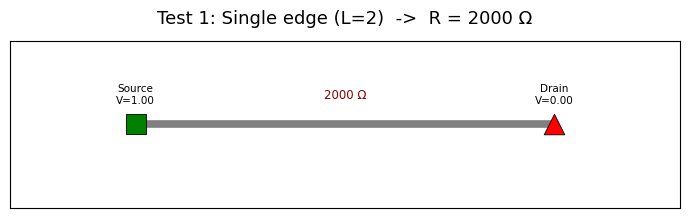

  [OK] Figure saved: test_1_single_edge.png


'<project_root>/utils/../experiments/exp_775/test_1_single_edge.png'

In [5]:
# Test 1: single edge (baseline), plus a quick backward-compatibility check:
# with unit spacing (L=1), the new model must match the old uniform-k model exactly.
intersections_1 = [[0.0, 0.0], [2.0, 0.0]]
graph_1 = [[0], [0]]
segment_to_nodes_1 = {0: (0, 1)}

calc_1 = ImpedanceCalculator(intersections_1, graph_1, segment_to_nodes_1)
result_1 = calc_1.calculate(k=1000.0, distance_dependent=True)
expected_1 = 1000.0 * 2.0
print(f"Got: {result_1['impedance']:.4f} ohm | Expected: {expected_1:.4f} ohm")
assert abs(result_1['impedance'] - expected_1) < 1e-6

result_unit = ImpedanceCalculator([[0, 0], [1, 0]], [[0], [0]], {0: (0, 1)}).calculate(
    k=1000.0, distance_dependent=True)
result_old = ImpedanceCalculator([[0, 0], [1, 0]], [[0], [0]], {0: (0, 1)}).calculate(k=1000.0)
assert abs(result_unit['impedance'] - result_old['impedance']) < 1e-6
print("PASSED (incl. backward-compatibility check at unit spacing)")

fig_1 = plot_small_network_with_impedance(
    intersections_1, segment_to_nodes_1, result_1, calc_1.source_node, calc_1.drain_node,
    title=f"Test 1: Single edge (L=2)  ->  R = {result_1['impedance']:.0f} \u03a9"
)
plt.show()
exp_manager.save_figure(fig_1, "test_1_single_edge.png")


Got: 1280.6248 ohm | Expected (pinv cross-check): 1280.6248 ohm
PASSED


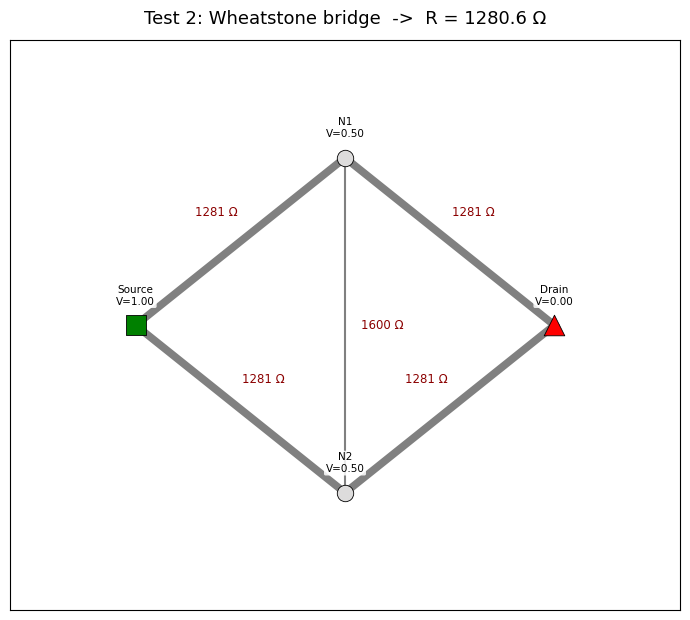

  [OK] Figure saved: test_2_wheatstone_bridge.png


'<project_root>/utils/../experiments/exp_775/test_2_wheatstone_bridge.png'

In [6]:
# Test 2: Wheatstone bridge -- 4 nodes, 5 edges, no simple series/parallel reduction.
# source=0, A=1, B=2, drain=3, bridge edge A-B.
intersections_2 = [
    [0.0, 0.0],   # 0 source
    [1.0, 0.8],   # 1 A
    [1.0, -0.8],  # 2 B
    [2.0, 0.0],   # 3 drain
]
graph_2 = [[0, 1], [0, 2, 4], [1, 3, 4], [2, 3]]
segment_to_nodes_2 = {
    0: (0, 1), 1: (0, 2), 2: (1, 3), 3: (2, 3), 4: (1, 2),  # edge 4 is the bridge
}

calc_2 = ImpedanceCalculator(intersections_2, graph_2, segment_to_nodes_2)
result_2 = calc_2.calculate(k=1000.0, distance_dependent=True)
expected_2 = effective_resistance_pinv(intersections_2, segment_to_nodes_2,
                                        calc_2.source_node, calc_2.drain_node, R0=1000.0)

print(f"Got: {result_2['impedance']:.4f} ohm | Expected (pinv cross-check): {expected_2:.4f} ohm")
assert abs(result_2['impedance'] - expected_2) < 1e-6, "Bridge test failed"
print("PASSED")

fig_2 = plot_small_network_with_impedance(
    intersections_2, segment_to_nodes_2, result_2, calc_2.source_node, calc_2.drain_node,
    title=f"Test 2: Wheatstone bridge  ->  R = {result_2['impedance']:.1f} \u03a9"
)
plt.show()
exp_manager.save_figure(fig_2, "test_2_wheatstone_bridge.png")


Source=0  Drain=5
Got: 1384.2461 ohm | Expected (pinv cross-check): 1384.2461 ohm
PASSED


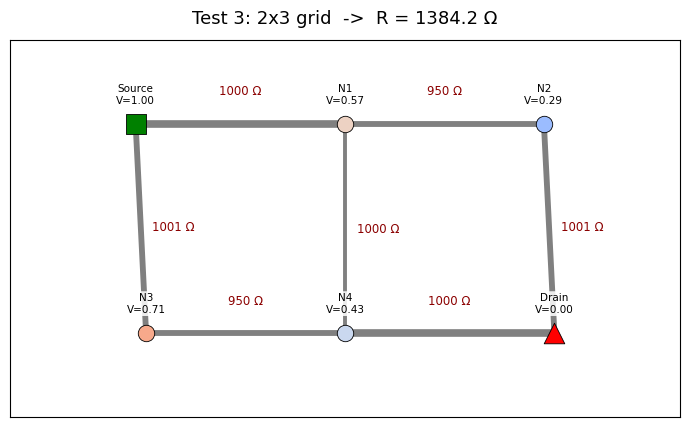

  [OK] Figure saved: test_3_grid.png


'<project_root>/utils/../experiments/exp_775/test_3_grid.png'

In [7]:
# Test 3: 2x3 grid/lattice, diagonal source (top-left) -> drain (bottom-right).
intersections_3 = [
    [0.00, 1.0], [1.00, 1.0], [1.95, 1.0],
    [0.05, 0.0], [1.00, 0.0], [2.00, 0.0],
]
segment_to_nodes_3 = {
    0: (0, 1), 1: (1, 2),              # top row
    2: (3, 4), 3: (4, 5),              # bottom row
    4: (0, 3), 5: (1, 4), 6: (2, 5),   # verticals
}
graph_3 = [[] for _ in range(6)]
for e, (a, b) in segment_to_nodes_3.items():
    graph_3[a].append(e)
    graph_3[b].append(e)

calc_3 = ImpedanceCalculator(intersections_3, graph_3, segment_to_nodes_3)
result_3 = calc_3.calculate(k=1000.0, distance_dependent=True)
expected_3 = effective_resistance_pinv(intersections_3, segment_to_nodes_3,
                                        calc_3.source_node, calc_3.drain_node, R0=1000.0)

print(f"Source={calc_3.source_node}  Drain={calc_3.drain_node}")
print(f"Got: {result_3['impedance']:.4f} ohm | Expected (pinv cross-check): {expected_3:.4f} ohm")
assert abs(result_3['impedance'] - expected_3) < 1e-6, "Grid test failed"
print("PASSED")

fig_3 = plot_small_network_with_impedance(
    intersections_3, segment_to_nodes_3, result_3, calc_3.source_node, calc_3.drain_node,
    title=f"Test 3: 2x3 grid  ->  R = {result_3['impedance']:.1f} \u03a9"
)
plt.show()
exp_manager.save_figure(fig_3, "test_3_grid.png")


Branch resistances: direct=3000.0  top=3650.3  bottom=3310.6
Got: 1099.6916 ohm | Expected (3-way parallel): 1099.6916 ohm
PASSED


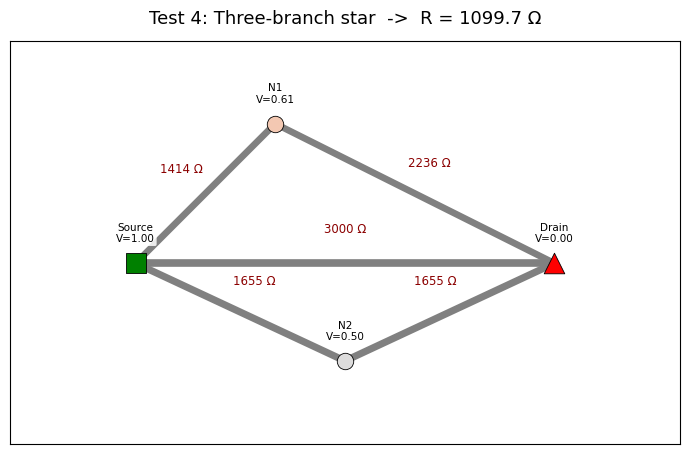

  [OK] Figure saved: test_4_star.png


'<project_root>/utils/../experiments/exp_775/test_4_star.png'

In [8]:
# Test 4: three-branch star -- one direct edge, plus two different 2-edge paths.
intersections_4 = [
    [0.0, 0.0],   # 0 source
    [1.0, 1.0],   # 1 top waypoint
    [1.5, -0.7],  # 2 bottom waypoint
    [3.0, 0.0],   # 3 drain
]
graph_4 = [[0, 1, 2], [0, 3], [1, 3], [2, 3]]
segment_to_nodes_4 = {
    0: (0, 3),  # direct branch
    1: (0, 1), 2: (1, 3),   # top branch (2 edges)
    3: (0, 2), 4: (2, 3),   # bottom branch (2 edges)
}

calc_4 = ImpedanceCalculator(intersections_4, graph_4, segment_to_nodes_4)
result_4 = calc_4.calculate(k=1000.0, distance_dependent=True)

L = result_4['edge_lengths']
R_direct = 1000.0 * L[0]
R_top = 1000.0 * (L[1] + L[2])
R_bottom = 1000.0 * (L[3] + L[4])
expected_4 = 1.0 / (1 / R_direct + 1 / R_top + 1 / R_bottom)

print(f"Branch resistances: direct={R_direct:.1f}  top={R_top:.1f}  bottom={R_bottom:.1f}")
print(f"Got: {result_4['impedance']:.4f} ohm | Expected (3-way parallel): {expected_4:.4f} ohm")
assert abs(result_4['impedance'] - expected_4) < 1e-6, "Star test failed"
print("PASSED")

fig_4 = plot_small_network_with_impedance(
    intersections_4, segment_to_nodes_4, result_4, calc_4.source_node, calc_4.drain_node,
    title=f"Test 4: Three-branch star  ->  R = {result_4['impedance']:.1f} \u03a9"
)
plt.show()
exp_manager.save_figure(fig_4, "test_4_star.png")


(a) 3 explicit parallel edges: 666.6667 ohm
(b) 1 edge with multiplier=3:  666.6667 ohm
PASSED -- multiplier and length combine correctly (G = multiplier / (R0*L))


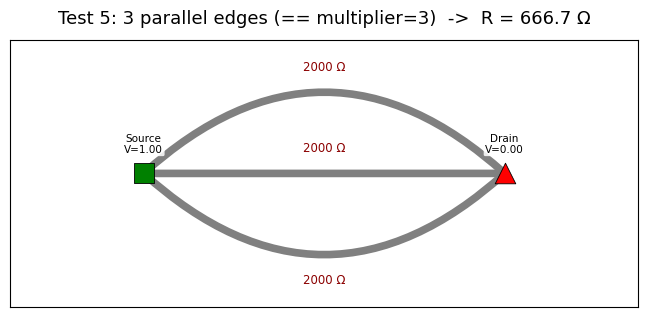

  [OK] Figure saved: test_5_multiplier.png


'<project_root>/utils/../experiments/exp_775/test_5_multiplier.png'

In [9]:
# Test 5: parallel-multiplier x length interaction. Compare (a) three explicit
# identical parallel edges against (b) one edge with edge_conductance multiplier=3
# (the representation merge_boundary_nodes produces for real networks) -- they
# must give the same result under distance_dependent=True.
intersections_5 = [[0.0, 0.0], [2.0, 0.0]]

graph_5a = [[0, 1, 2], [0, 1, 2]]
segment_to_nodes_5a = {0: (0, 1), 1: (0, 1), 2: (0, 1)}
calc_5a = ImpedanceCalculator(intersections_5, graph_5a, segment_to_nodes_5a)
result_5a = calc_5a.calculate(k=1000.0, distance_dependent=True)

graph_5b = [[0], [0]]
segment_to_nodes_5b = {0: (0, 1)}
calc_5b = ImpedanceCalculator(intersections_5, graph_5b, segment_to_nodes_5b,
                              edge_conductance={0: 3})
result_5b = calc_5b.calculate(k=1000.0, distance_dependent=True)

print(f"(a) 3 explicit parallel edges: {result_5a['impedance']:.4f} ohm")
print(f"(b) 1 edge with multiplier=3:  {result_5b['impedance']:.4f} ohm")
expected_5 = (1000.0 * 2.0) / 3.0
assert abs(result_5a['impedance'] - result_5b['impedance']) < 1e-6
assert abs(result_5b['impedance'] - expected_5) < 1e-6, "Multiplier interaction test failed"
print("PASSED -- multiplier and length combine correctly (G = multiplier / (R0*L))")

fig_5 = plot_small_network_with_impedance(
    intersections_5, segment_to_nodes_5a, result_5a, calc_5a.source_node, calc_5a.drain_node,
    title=f"Test 5: 3 parallel edges (== multiplier=3)  ->  R = {result_5a['impedance']:.1f} \u03a9"
)
plt.show()
exp_manager.save_figure(fig_5, "test_5_multiplier.png")


Got: 4000.0000 ohm | Expected (stub ignored): 4000.0000 ohm
Current through the stub (edge 2): 1.11e-19 A
PASSED


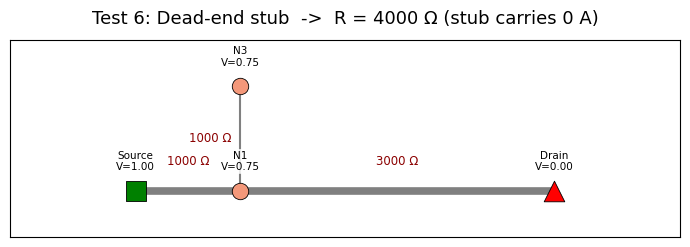


ALL 6 UNIT TESTS PASSED
  [OK] Figure saved: test_6_dead_end.png


'<project_root>/utils/../experiments/exp_775/test_6_dead_end.png'

In [10]:
# Test 6: dead-end / dangling branch robustness. Same series path as Test 1's
# spirit (two edges in series, lengths 1 and 3) plus a stub edge hanging off the
# middle node that goes nowhere. The stub must not change R_total, and must
# carry ~zero current.
intersections_6 = [[0.0, 0.0], [1.0, 0.0], [4.0, 0.0], [1.0, 1.0]]
graph_6 = [[0], [0, 1, 2], [1], [2]]
segment_to_nodes_6 = {0: (0, 1), 1: (1, 2), 2: (1, 3)}  # edge 2 is the dead-end stub

calc_6 = ImpedanceCalculator(intersections_6, graph_6, segment_to_nodes_6)
result_6 = calc_6.calculate(k=1000.0, distance_dependent=True)

expected_6 = 1000.0 * 1.0 + 1000.0 * 3.0  # stub should not matter
print(f"Got: {result_6['impedance']:.4f} ohm | Expected (stub ignored): {expected_6:.4f} ohm")
print(f"Current through the stub (edge 2): {result_6['currents'][2]:.2e} A")
assert abs(result_6['impedance'] - expected_6) < 1e-6, "Dead-end test failed"
assert abs(result_6['currents'][2]) < 1e-9, "Stub should carry no current"
print("PASSED")

fig_6 = plot_small_network_with_impedance(
    intersections_6, segment_to_nodes_6, result_6, calc_6.source_node, calc_6.drain_node,
    title=f"Test 6: Dead-end stub  ->  R = {result_6['impedance']:.0f} \u03a9 (stub carries 0 A)"
)
plt.show()

print("\nALL 6 UNIT TESTS PASSED")
exp_manager.save_figure(fig_6, "test_6_dead_end.png")


---
## 4. Six applications to real random stick networks

In [11]:
def generate_percolating_network(N, a, k_uniform=1000.0, max_attempts=60, seed=None):
    """Retry point generation until a percolating network is found. Silences
    run_full_pipeline's internal per-attempt prints so a sparse/near-threshold
    network doesn't spam dozens of 'Boundary conditions not met' lines."""
    if seed is not None:
        np.random.seed(seed)
    for attempt in range(max_attempts):
        points_1, points_2, angles = [], [], []
        generate_points(N, points_1, points_2, angles, a, enforce_bounds=True)
        with contextlib.redirect_stdout(io.StringIO()):
            results = run_full_pipeline(points_1, points_2, angles, N, a, k=k_uniform, verbose=False)
        if results.get("has_percolation") and "merged_segment_to_nodes" in results:
            results["points_1"] = points_1
            results["points_2"] = points_2
            results["angles"] = angles
            return results, attempt + 1
    raise RuntimeError(f"No percolating network found in {max_attempts} attempts (N={N}, a={a})")


def distance_dependent_result(results, R0):
    calc = ImpedanceCalculator(
        results["merged_intersections"], results["merged_graph"],
        results["merged_segment_to_nodes"], edge_conductance=results["edge_conductance"],
    )
    return calc.calculate(k=R0, distance_dependent=True)


print("Helpers defined")


Helpers defined


### 4.1 Baseline network (N=30, a=0.6)

Percolating network found on attempt 2
  Nodes/edges (merged): 120/211
  Uniform R (k=1000/edge):        2449.0764 ohm
  Distance-dependent (R0=1000*L): 218.0881 ohm


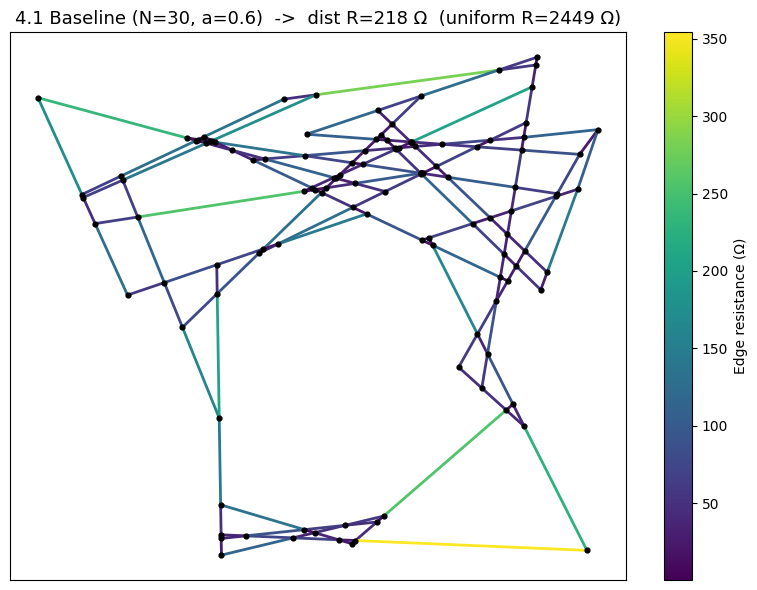

  [OK] Figure saved: 4.1_baseline_network.png
  [OK] JSON saved: network_4.1_baseline.json


'<project_root>/utils/../experiments/exp_775/network_4.1_baseline.json'

In [12]:
R0 = 1000.0
results_1, attempts_1 = generate_percolating_network(N=30, a=0.6, k_uniform=R0, seed=42)
result_len_1 = distance_dependent_result(results_1, R0)

print(f"Percolating network found on attempt {attempts_1}")
print(f"  Nodes/edges (merged): {len(results_1['merged_intersections'])}/{len(results_1['merged_segment_to_nodes'])}")
print(f"  Uniform R (k={R0:.0f}/edge):        {results_1['impedance']:.4f} ohm")
print(f"  Distance-dependent (R0={R0:.0f}*L): {result_len_1['impedance']:.4f} ohm")

fig = plot_network_colored_by_resistance(
    results_1['merged_intersections'], results_1['merged_segment_to_nodes'],
    result_len_1['edge_resistances'],
    title=f"4.1 Baseline (N=30, a=0.6)  ->  dist R={result_len_1['impedance']:.0f} \u03a9  "
          f"(uniform R={results_1['impedance']:.0f} \u03a9)"
)
plt.show()
exp_manager.save_figure(fig, "4.1_baseline_network.png")
exp_manager.save_network(30, 0.6, results_1['points_1'], results_1['points_2'], results_1['angles'], filename="network_4.1_baseline.json")


### 4.2 Longer sticks (a=0.9)

Bigger aspect ratio -> fewer, longer sticks -> fewer, longer segments between intersections.

Percolating network found on attempt 1
  Uniform R:             2234.2067 ohm
  Distance-dependent R:  150.5611 ohm


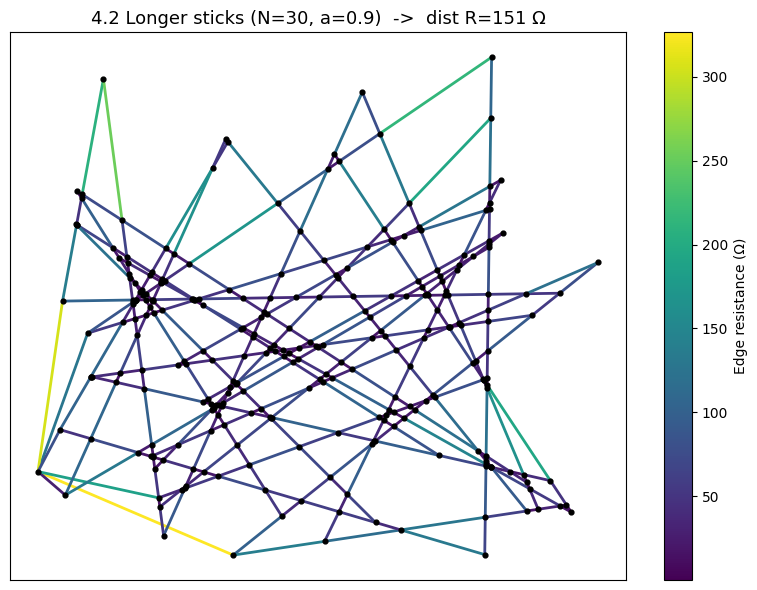

  [OK] Figure saved: 4.2_longer_sticks_network.png
  [OK] JSON saved: network_4.2_longer_sticks.json


'<project_root>/utils/../experiments/exp_775/network_4.2_longer_sticks.json'

In [13]:
results_2, attempts_2 = generate_percolating_network(N=30, a=0.9, k_uniform=R0, seed=1)
result_len_2 = distance_dependent_result(results_2, R0)

print(f"Percolating network found on attempt {attempts_2}")
print(f"  Uniform R:             {results_2['impedance']:.4f} ohm")
print(f"  Distance-dependent R:  {result_len_2['impedance']:.4f} ohm")

fig = plot_network_colored_by_resistance(
    results_2['merged_intersections'], results_2['merged_segment_to_nodes'],
    result_len_2['edge_resistances'],
    title=f"4.2 Longer sticks (N=30, a=0.9)  ->  dist R={result_len_2['impedance']:.0f} \u03a9"
)
plt.show()
exp_manager.save_figure(fig, "4.2_longer_sticks_network.png")
exp_manager.save_network(30, 0.9, results_2['points_1'], results_2['points_2'], results_2['angles'], filename="network_4.2_longer_sticks.json")


### 4.3 Denser network (N=60)

Percolating network found on attempt 1
  Uniform R:             2862.0975 ohm
  Distance-dependent R:  155.8113 ohm


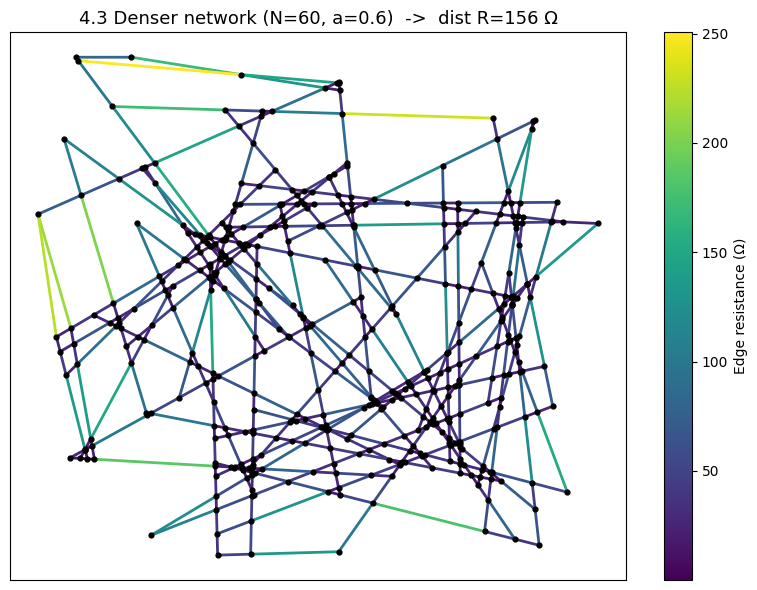

  [OK] Figure saved: 4.3_denser_network.png
  [OK] JSON saved: network_4.3_denser.json


'<project_root>/utils/../experiments/exp_775/network_4.3_denser.json'

In [14]:
results_3, attempts_3 = generate_percolating_network(N=60, a=0.6, k_uniform=R0, seed=2)
result_len_3 = distance_dependent_result(results_3, R0)

print(f"Percolating network found on attempt {attempts_3}")
print(f"  Uniform R:             {results_3['impedance']:.4f} ohm")
print(f"  Distance-dependent R:  {result_len_3['impedance']:.4f} ohm")

fig = plot_network_colored_by_resistance(
    results_3['merged_intersections'], results_3['merged_segment_to_nodes'],
    result_len_3['edge_resistances'],
    title=f"4.3 Denser network (N=60, a=0.6)  ->  dist R={result_len_3['impedance']:.0f} \u03a9"
)
plt.show()
exp_manager.save_figure(fig, "4.3_denser_network.png")
exp_manager.save_network(60, 0.6, results_3['points_1'], results_3['points_2'], results_3['angles'], filename="network_4.3_denser.json")


### 4.4 Sparse / near-percolation-threshold network (N=15, a=0.8)

Percolating network found on attempt 33 (sparse networks need more retries)
  Uniform R:             2018.1681 ohm
  Distance-dependent R:  274.4020 ohm


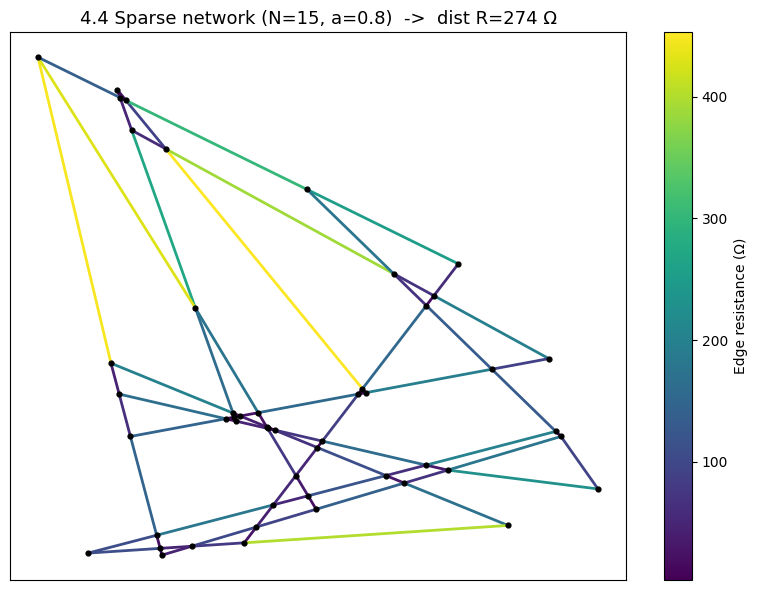

  [OK] Figure saved: 4.4_sparse_network.png
  [OK] JSON saved: network_4.4_sparse.json


'<project_root>/utils/../experiments/exp_775/network_4.4_sparse.json'

In [15]:
results_4, attempts_4 = generate_percolating_network(N=15, a=0.8, k_uniform=R0, max_attempts=200, seed=3)
result_len_4 = distance_dependent_result(results_4, R0)

print(f"Percolating network found on attempt {attempts_4} (sparse networks need more retries)")
print(f"  Uniform R:             {results_4['impedance']:.4f} ohm")
print(f"  Distance-dependent R:  {result_len_4['impedance']:.4f} ohm")

fig = plot_network_colored_by_resistance(
    results_4['merged_intersections'], results_4['merged_segment_to_nodes'],
    result_len_4['edge_resistances'],
    title=f"4.4 Sparse network (N=15, a=0.8)  ->  dist R={result_len_4['impedance']:.0f} \u03a9"
)
plt.show()
exp_manager.save_figure(fig, "4.4_sparse_network.png")
exp_manager.save_network(15, 0.8, results_4['points_1'], results_4['points_2'], results_4['angles'], filename="network_4.4_sparse.json")


### 4.5 $R_0$ sweep on one fixed network

The equivalent resistance must scale exactly linearly with $R_0$ -- a good sanity check on its own.

  R0=   250 ohm  ->  R_total=   83.5388 ohm   (R_total / R0 = 0.334155)
  R0=   500 ohm  ->  R_total=  167.0777 ohm   (R_total / R0 = 0.334155)
  R0=  1000 ohm  ->  R_total=  334.1553 ohm   (R_total / R0 = 0.334155)
  R0=  2000 ohm  ->  R_total=  668.3106 ohm   (R_total / R0 = 0.334155)
  R0=  4000 ohm  ->  R_total= 1336.6212 ohm   (R_total / R0 = 0.334155)
PASSED -- perfectly linear in R0, as expected


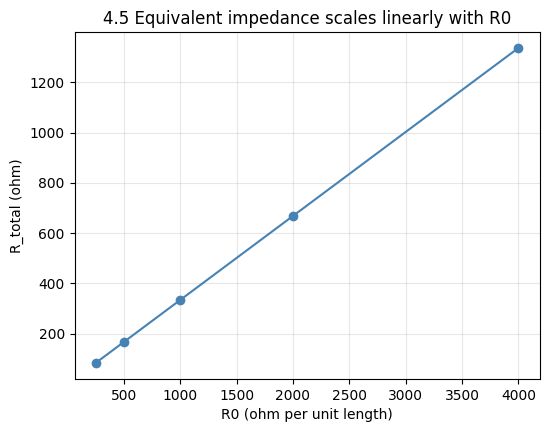

  [OK] Figure saved: 4.5_R0_sweep.png
  [OK] JSON saved: network_4.5_r0_sweep.json


'<project_root>/utils/../experiments/exp_775/network_4.5_r0_sweep.json'

In [16]:
results_5, attempts_5 = generate_percolating_network(N=30, a=0.6, k_uniform=R0, seed=4)

R0_values = [250.0, 500.0, 1000.0, 2000.0, 4000.0]
R_totals = []
for r0 in R0_values:
    r = distance_dependent_result(results_5, r0)["impedance"]
    R_totals.append(r)
    print(f"  R0={r0:>6.0f} ohm  ->  R_total={r:>10.4f} ohm   (R_total / R0 = {r / r0:.6f})")

ratios = np.array(R_totals) / np.array(R0_values)
assert np.allclose(ratios, ratios[0], rtol=1e-9), "Impedance should scale exactly linearly with R0"
print("PASSED -- perfectly linear in R0, as expected")

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(R0_values, R_totals, 'o-', color='steelblue')
ax.set_xlabel('R0 (ohm per unit length)')
ax.set_ylabel('R_total (ohm)')
ax.set_title('4.5 Equivalent impedance scales linearly with R0')
ax.grid(True, alpha=0.3)
plt.show()
exp_manager.save_figure(fig, "4.5_R0_sweep.png")
exp_manager.save_network(30, 0.6, results_5['points_1'], results_5['points_2'], results_5['angles'], filename="network_4.5_r0_sweep.json")


### 4.6 Monte Carlo across many random realizations

Same (N, a) generated 15 times -- how consistent is the gap between the two models?

Over 15 independent random networks (N=30, a=0.6):
  Uniform R:            mean=2937.9  std=877.8 ohm
  Distance-dependent R: mean=287.2  std=113.1 ohm
  Ratio (dist/uniform): mean=0.0972  std=0.0212


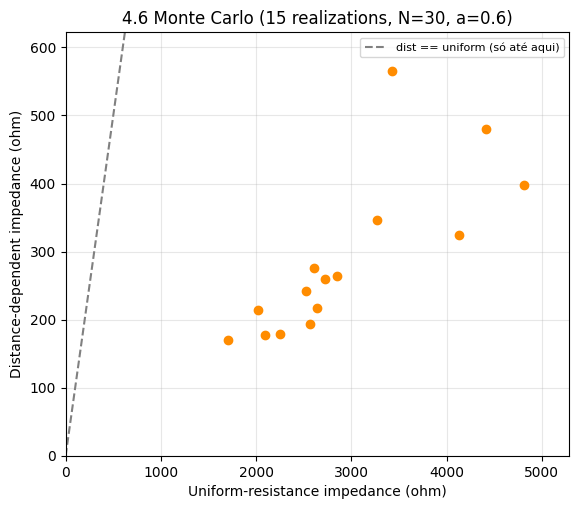

  [OK] Figure saved: 4.6_monte_carlo_scatter.png
  [OK] JSON saved: monte_carlo_results.json


'<project_root>/utils/../experiments/exp_775/monte_carlo_results.json'

In [17]:
n_trials = 15
uniform_list, dist_list = [], []
np.random.seed(5)
for trial in range(n_trials):
    res, _ = generate_percolating_network(N=30, a=0.6, k_uniform=R0)
    rl = distance_dependent_result(res, R0)
    uniform_list.append(res['impedance'])
    dist_list.append(rl['impedance'])

uniform_arr = np.array(uniform_list)
dist_arr = np.array(dist_list)
ratio = dist_arr / uniform_arr

print(f"Over {n_trials} independent random networks (N=30, a=0.6):")
print(f"  Uniform R:            mean={uniform_arr.mean():.1f}  std={uniform_arr.std():.1f} ohm")
print(f"  Distance-dependent R: mean={dist_arr.mean():.1f}  std={dist_arr.std():.1f} ohm")
print(f"  Ratio (dist/uniform): mean={ratio.mean():.4f}  std={ratio.std():.4f}")

fig, ax = plt.subplots(figsize=(6.5, 5.5))

# Each axis is scaled to its OWN data range, not forced to share one scale --
# forcing both onto the same range (as a naive y=x reference plot would)
# squeezes the much-smaller distance-dependent values into a thin sliver near
# the bottom, which is hard to read correctly.
x_max = uniform_arr.max() * 1.1
y_max = dist_arr.max() * 1.1
diag_max = min(x_max, y_max)  # y=x is only meaningful where both axes overlap

ax.plot([0, diag_max], [0, diag_max], '--', color='gray', label='dist == uniform (só até aqui)')
ax.scatter(uniform_arr, dist_arr, color='darkorange', zorder=3)
ax.set_xlim(0, x_max)
ax.set_ylim(0, y_max)
ax.set_xlabel('Uniform-resistance impedance (ohm)')
ax.set_ylabel('Distance-dependent impedance (ohm)')
ax.set_title(f'4.6 Monte Carlo ({n_trials} realizations, N=30, a=0.6)')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.show()
exp_manager.save_figure(fig, "4.6_monte_carlo_scatter.png")
exp_manager.save_json(
    {"N": 30, "a": 0.6, "n_trials": n_trials,
     "uniform_impedance": uniform_list, "distance_dependent_impedance": dist_list,
     "ratio": ratio.tolist()},
    "monte_carlo_results.json"
)


---
## 5. Save consolidated summary

In [18]:
summary = {
    "experiment": exp_manager.get_info(),
    "unit_tests": {
        "test_1_single_edge": result_1['impedance'],
        "test_2_wheatstone_bridge": result_2['impedance'],
        "test_3_grid": result_3['impedance'],
        "test_4_star": result_4['impedance'],
        "test_5_multiplier_a_explicit_parallel": result_5a['impedance'],
        "test_5_multiplier_b_edge_conductance": result_5b['impedance'],
        "test_6_dead_end": result_6['impedance'],
    },
    "demo_networks": {
        "4.1_baseline": {"N": 30, "a": 0.6, "attempts": attempts_1,
                          "uniform_R": results_1['impedance'], "distance_R": result_len_1['impedance']},
        "4.2_longer_sticks": {"N": 30, "a": 0.9, "attempts": attempts_2,
                               "uniform_R": results_2['impedance'], "distance_R": result_len_2['impedance']},
        "4.3_denser": {"N": 60, "a": 0.6, "attempts": attempts_3,
                        "uniform_R": results_3['impedance'], "distance_R": result_len_3['impedance']},
        "4.4_sparse": {"N": 15, "a": 0.8, "attempts": attempts_4,
                        "uniform_R": results_4['impedance'], "distance_R": result_len_4['impedance']},
    },
    "r0_sweep": {"N": 30, "a": 0.6, "R0_values": R0_values, "R_totals": R_totals},
    "monte_carlo": {
        "N": 30, "a": 0.6, "n_trials": n_trials,
        "uniform_mean": float(uniform_arr.mean()), "uniform_std": float(uniform_arr.std()),
        "distance_mean": float(dist_arr.mean()), "distance_std": float(dist_arr.std()),
        "ratio_mean": float(ratio.mean()), "ratio_std": float(ratio.std()),
    },
}

exp_manager.save_json(summary, "distance_dependent_summary.json")

print(f"\nAll results saved to: {exp_manager.experiment_dir}")
for f in sorted(os.listdir(exp_manager.experiment_dir)):
    print(f"  - {f}")


  [OK] JSON saved: distance_dependent_summary.json

All results saved to: <project_root>/utils/../experiments/exp_775
  - 4.1_baseline_network.png
  - 4.2_longer_sticks_network.png
  - 4.3_denser_network.png
  - 4.4_sparse_network.png
  - 4.5_R0_sweep.png
  - 4.6_monte_carlo_scatter.png
  - distance_dependent_summary.json
  - monte_carlo_results.json
  - network_4.1_baseline.json
  - network_4.2_longer_sticks.json
  - network_4.3_denser.json
  - network_4.4_sparse.json
  - network_4.5_r0_sweep.json
  - test_1_single_edge.png
  - test_2_wheatstone_bridge.png
  - test_3_grid.png
  - test_4_star.png
  - test_5_multiplier.png
  - test_6_dead_end.png
